## Objectives

In this self-study lab you will

1. implement the squared-error cost function $J(w,b)$, first with a loop and then vectorised;
2. visualise $J$ as a function of $w$ alone (with $b = 0$) and as a function of both $w$ and $b$;
3. compute the best parameters with the closed-form solution and compare them with scikit-learn;
4. implement the gradient of $J$ and check it with finite differences;
5. implement gradient descent and study how the learning rate $\alpha$ affects convergence.

## Tools

In this lab you will use

- **NumPy** and **Matplotlib**, as in Lab 1;
- **scikit-learn**, to load the data and as a reference solution;
- **ipywidgets** (optional), for an interactive plot with sliders in Jupyter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression

## Data

We use the two data sets from the lecture:

1. the **toy data set** with $m = 3$ examples $(1, 1)$, $(2, 2)$, $(3, 3)$, small enough to check every result by hand;
2. the **diabetes data set** from Lab 1, with BMI as input $x$ and disease progression as target $y$.

In [2]:
# Toy data set from the lecture
x_toy = np.array([1.0, 2.0, 3.0])
y_toy = np.array([1.0, 2.0, 3.0])

# Diabetes data set (see Lab 1): BMI -> disease progression
diabetes = load_diabetes(scaled=False)
x_train = diabetes.data[:, diabetes.feature_names.index('bmi')]
y_train = diabetes.target

## Computing the cost

The squared-error cost function is
$$
J(w,b) = \frac{1}{2m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)^2,
\qquad f_{w,b}(x^{(i)}) = w x^{(i)} + b .
$$

- $f_{w,b}(x^{(i)}) = \hat y^{(i)}$ is the prediction for example $i$.
- $\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)^2$ is the squared error of example $i$.
- The squared errors are averaged over all $m$ examples. The extra factor $\frac12$ only makes the derivatives tidier; it does not change where the minimum is.

::: {.callout-note title="Indexing in the code"}
In the lecture the sum runs from $i = 1$ to $m$. In Python, `range(m)` runs from `0` to `m-1`, so `x[i]` in the code is $x^{(i+1)}$ in the formula. Both describe the same sum over all examples.
:::

The first implementation follows the formula term by term.

In [3]:
def compute_cost_loop(x, y, w, b):
    """
    Compute the squared-error cost J(w,b) with a for loop.

    Args:
        x (ndarray (m,)): input values, m examples
        y (ndarray (m,)): target values
        w, b (scalar)   : model parameters
    Returns:
        cost (float): the cost J(w,b)
    """
    m = x.shape[0]
    cost_sum = 0.0
    for i in range(m):
        f_wb_i = w * x[i] + b                       # prediction for example i
        cost_sum = cost_sum + (f_wb_i - y[i]) ** 2  # add its squared error
    return cost_sum / (2 * m)

**Challenge:** rewrite the function without the `for` loop. Compute all predictions at once as in Lab 1, then use `np.sum()`.

::: {.callout-tip collapse="true" title="Solution"}

In [4]:
def compute_cost(x, y, w, b):
    """Vectorised squared-error cost J(w,b)."""
    m = x.shape[0]
    err = w * x + b - y              # prediction errors of all m examples
    return np.sum(err ** 2) / (2 * m)

:::

We test both versions against the values computed by hand in the lecture: $J(1, 0) = 0$, $J(0.5, 0) = \frac{7}{12} \approx 0.583$ and $J(0, 0) = \frac{7}{3} \approx 2.333$.

In [5]:
for w in [1.0, 0.5, 0.0]:
    print(f"w = {w}: loop {compute_cost_loop(x_toy, y_toy, w, 0.0):.4f}, "
          f"vectorised {compute_cost(x_toy, y_toy, w, 0.0):.4f}")

w = 1.0: loop 0.0000, vectorised 0.0000
w = 0.5: loop 0.5833, vectorised 0.5833
w = 0.0: loop 2.3333, vectorised 2.3333


## Cost function intuition

### One parameter: fix $b = 0$

With $b = 0$ the model is $f_w(x) = wx$, a line through the origin, and the cost depends on $w$ only. In the lecture we found $J(w) = \frac{7}{3}(w - 1)^2$ for the toy data. Each value of $w$ on the right-hand plot corresponds to one line on the left-hand plot.

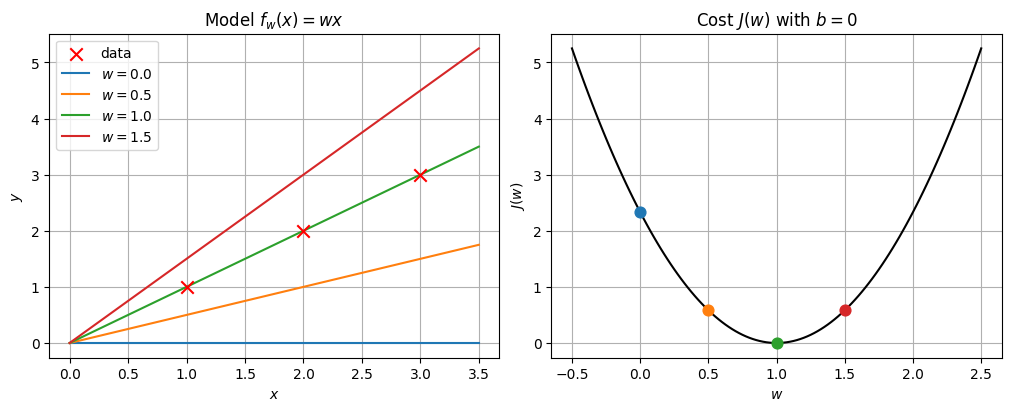

In [6]:
w_values = np.linspace(-0.5, 2.5, 121)
J_values = [compute_cost(x_toy, y_toy, w, 0.0) for w in w_values]
w_marked = [0.0, 0.5, 1.0, 1.5]
x_line = np.array([0.0, 3.5])

fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
ax[0].scatter(x_toy, y_toy, marker='x', c='r', s=80, zorder=3, label='data')
ax[1].plot(w_values, J_values, 'k-')
for k, w in enumerate(w_marked):
    ax[0].plot(x_line, w * x_line, color=f'C{k}', label=f'$w = {w}$')
    ax[1].scatter(w, compute_cost(x_toy, y_toy, w, 0.0), color=f'C{k}', s=60, zorder=3)
ax[0].set(xlabel='$x$', ylabel='$y$', title='Model $f_w(x) = wx$')
ax[0].legend()
ax[1].set(xlabel='$w$', ylabel='$J(w)$', title='Cost $J(w)$ with $b = 0$')
for a in ax:
    a.grid(True)
plt.show()

The cost is a parabola with its minimum $J = 0$ at $w = 1$, where the line passes through all three points.

::: {.callout-note title="Interactive version (Jupyter only)"}
The sliders below need a running Python kernel, so this cell is not executed in the HTML version. Run it in Jupyter to change $w$ and $b$ and watch the line, the prediction errors (dashed) and the cost.
:::

In [ ]:
#| eval: false
from ipywidgets import interact, FloatSlider

@interact(w=FloatSlider(value=0.5, min=-0.5, max=2.5, step=0.05, continuous_update=False),
          b=FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.1, continuous_update=False))
def explore_cost(w, b):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    ax[0].scatter(x_toy, y_toy, marker='x', c='r', s=80, zorder=3)
    ax[0].plot(x_line, w * x_line + b, 'b-')
    ax[0].vlines(x_toy, w * x_toy + b, y_toy, colors='m', linestyles='--')
    ax[0].set(xlabel='$x$', ylabel='$y$', title=f'Model: w = {w:.2f}, b = {b:.2f}')
    ax[1].plot(w_values, [compute_cost(x_toy, y_toy, wi, b) for wi in w_values], 'k-')
    ax[1].scatter(w, compute_cost(x_toy, y_toy, w, b), c='m', s=80, zorder=3)
    ax[1].set(xlabel='$w$', ylabel=f'$J(w, b = {b:.1f})$',
              title=f'Current cost = {compute_cost(x_toy, y_toy, w, b):.3f}')
    for a in ax:
        a.grid(True)
    plt.show()

### Two parameters: surface and contour plots

To see $J$ as a function of both $w$ and $b$, we evaluate it on a grid of $(w, b)$ values. `np.meshgrid` builds the grid.

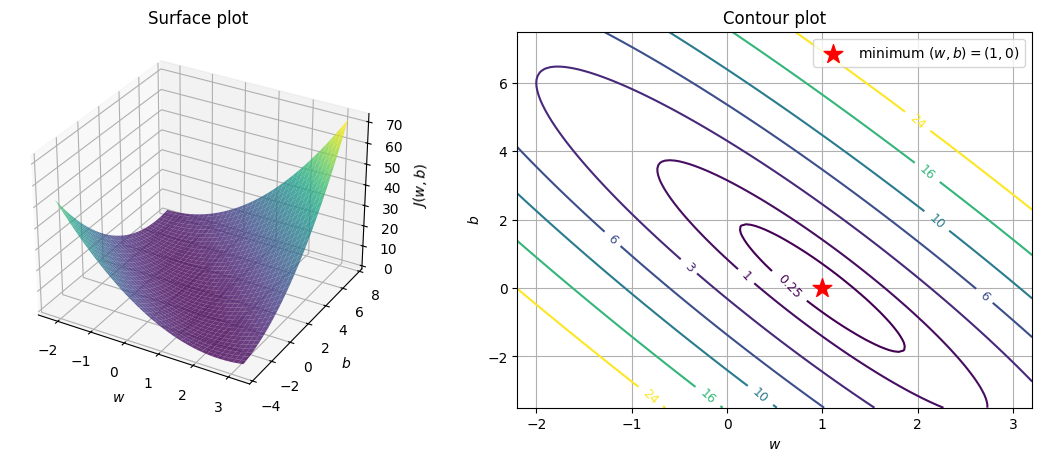

In [8]:
def cost_on_grid(x, y, w_values, b_values):
    """Evaluate J(w,b) for all pairs (w, b) from w_values and b_values."""
    W, B = np.meshgrid(w_values, b_values)   # W[i, j] = w_values[j], B[i, j] = b_values[i]
    J = np.zeros_like(W)
    for i in range(W.shape[0]):
        for j in range(W.shape[1]):
            J[i, j] = compute_cost(x, y, W[i, j], B[i, j])
    return W, B, J

W, B, J_grid = cost_on_grid(x_toy, y_toy, np.linspace(-2.2, 3.2, 109), np.linspace(-3.5, 7.5, 111))
levels = [0.25, 1, 3, 6, 10, 16, 24]

fig = plt.figure(figsize=(11, 4.5), constrained_layout=True)
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(W, B, J_grid, cmap='viridis', alpha=0.8)
ax1.set(xlabel='$w$', ylabel='$b$', zlabel='$J(w,b)$', title='Surface plot')
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(W, B, J_grid, levels=levels, cmap='viridis')
ax2.clabel(cs, fmt='%g', fontsize=9)
ax2.scatter(1, 0, marker='*', c='r', s=200, zorder=3, label='minimum $(w, b) = (1, 0)$')
ax2.set(xlabel='$w$', ylabel='$b$', title='Contour plot')
ax2.legend()
ax2.grid(True)
plt.show()

As in the lecture, $J(w,b)$ is a **bowl** with a single minimum $J = 0$ at $(w, b) = (1, 0)$, i.e. the line $\hat y = x$. The contour ellipses are tilted because $w$ and $b$ are coupled: the expansion of $J$ contains the mixed term $2(w-1)b$.

## Minimising the cost: the closed-form solution

Since $J$ is a sum of squares, $J \ge 0$, and $J = 0$ exactly when every data point lies on the line. This happens for the toy data, but no straight line passes through all $442$ diabetes patients, so there the smallest possible cost is positive.

In the lecture we solved $\nabla J = \mathbf 0$ and found the minimiser
$$
w^* = \frac{\overline{xy} - \bar x\,\bar y}{\overline{x^2} - \bar x^2},
\qquad
b^* = \bar y - w^*\,\bar x ,
$$
where a bar denotes the average over the training set, e.g. $\overline{xy} = \frac1m\sum_{i} x^{(i)}y^{(i)}$. The denominator is zero only if all $x^{(i)}$ are equal.

In [9]:
def fit_closed_form(x, y):
    """Minimiser (w*, b*) of the squared-error cost for univariate linear regression."""
    x_mean, y_mean = np.mean(x), np.mean(y)
    w = (np.mean(x * y) - x_mean * y_mean) / (np.mean(x ** 2) - x_mean ** 2)
    b = y_mean - w * x_mean
    return w, b

w_toy, b_toy = fit_closed_form(x_toy, y_toy)
print(f"Toy data:      w* = {w_toy:.4f}, b* = {b_toy:.4f}, "
      f"J = {compute_cost(x_toy, y_toy, w_toy, b_toy):.4f}")

w_star, b_star = fit_closed_form(x_train, y_train)
J_min = compute_cost(x_train, y_train, w_star, b_star)
print(f"Diabetes data: w* = {w_star:.4f}, b* = {b_star:.4f}, J = {J_min:.4f}")

Toy data:      w* = 1.0000, b* = 0.0000, J = 0.0000
Diabetes data: w* = 10.2331, b* = -117.7734, J = 1945.2283


For the diabetes data we recover the line $\hat y = 10.23\,x - 117.77$ from the lecture, with a minimum cost of about $1945$. The vertical segments in the plot below are the prediction errors $\hat y^{(i)} - y^{(i)}$; even the best line cannot make them all zero.

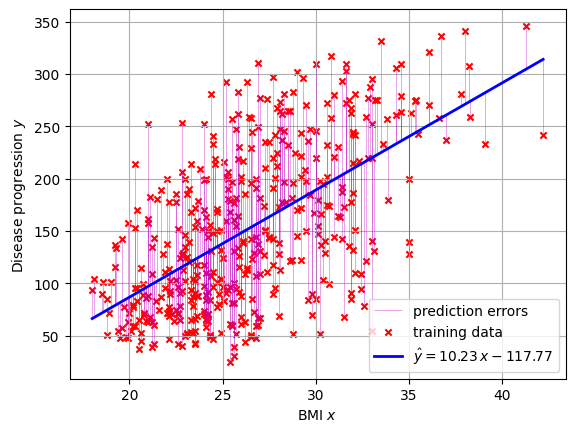

In [10]:
x_line = np.array([x_train.min(), x_train.max()])
plt.vlines(x_train, w_star * x_train + b_star, y_train, colors='m', lw=0.5, alpha=0.5,
           label='prediction errors')
plt.scatter(x_train, y_train, marker='x', c='r', s=20, label='training data')
plt.plot(x_line, w_star * x_line + b_star, 'b-', lw=2,
         label=f'$\\hat{{y}} = {w_star:.2f}\\,x {b_star:+.2f}$')
plt.xlabel('BMI $x$')
plt.ylabel('Disease progression $y$')
plt.legend()
plt.grid(True)
plt.show()

### Comparison with scikit-learn

scikit-learn's `LinearRegression` solves the same least-squares problem with a direct linear-algebra solver, so it must give the same answer up to round-off.

In [11]:
model = LinearRegression()
model.fit(x_train.reshape(-1, 1), y_train)
print(f"scikit-learn:  w = {model.coef_[0]:.4f}, b = {model.intercept_:.4f}")

scikit-learn:  w = 10.2331, b = -117.7734


scikit-learn expects the inputs as a 2D array of shape `(m, n_features)`, one column per feature. `x_train.reshape(-1, 1)` turns the 1D array of length $m$ into a single column; the `-1` means "work out this size from the data". The fitted weights are stored in the array `model.coef_` (one entry per feature) and the bias in `model.intercept_`. With several features, the closed-form solution becomes the **normal equation** of part 2b of the lecture (Lab 5).

For almost every model other than linear regression, $\nabla J = \mathbf 0$ cannot be solved in closed form. We therefore now implement the general, iterative method: gradient descent.

## Gradient descent

### The gradient of the cost

From the lecture, the partial derivatives of $J$ are
$$
\frac{\partial J}{\partial w} = \frac{1}{m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)\,x^{(i)},
\qquad
\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big).
$$

In [12]:
def compute_gradient(x, y, w, b):
    """
    Compute the gradient of the squared-error cost J(w,b).

    Args:
        x, y (ndarray (m,)): training data
        w, b (scalar)      : model parameters
    Returns:
        dJ_dw, dJ_db (float): partial derivatives of J with respect to w and b
    """
    m = x.shape[0]
    err = w * x + b - y
    dJ_dw = np.sum(err * x) / m
    dJ_db = np.sum(err) / m
    return dJ_dw, dJ_db

For the toy data the lecture gives $\frac{\partial J}{\partial w} = \frac{14}{3}(w-1) + 2b$ and $\frac{\partial J}{\partial b} = 2(w-1) + b$. Let us compare at $(w, b) = (-1.5, 6)$:

In [13]:
w, b = -1.5, 6.0
dJ_dw, dJ_db = compute_gradient(x_toy, y_toy, w, b)
print(f"compute_gradient: dJ/dw = {dJ_dw:.4f}, dJ/db = {dJ_db:.4f}")
print(f"lecture formulas: dJ/dw = {14/3 * (w - 1) + 2 * b:.4f}, dJ/db = {2 * (w - 1) + b:.4f}")

compute_gradient: dJ/dw = 0.3333, dJ/db = 1.0000
lecture formulas: dJ/dw = 0.3333, dJ/db = 1.0000


### Checking the gradient with finite differences

Errors in gradient code are common and hard to spot, because gradient descent may still run, just badly. A standard check compares the code with a **finite-difference** approximation. For a function $g$ of one variable and a small number $\varepsilon$, the central difference is
$$
g'(x_0) \approx \frac{g(x_0 + \varepsilon) - g(x_0 - \varepsilon)}{2\varepsilon} .
$$
For the partial derivatives of $J$, we change one parameter at a time:
$$
\frac{\partial J}{\partial w}(w_0, b_0) \approx \frac{J(w_0 + \varepsilon, b_0) - J(w_0 - \varepsilon, b_0)}{2\varepsilon},
\qquad
\frac{\partial J}{\partial b}(w_0, b_0) \approx \frac{J(w_0, b_0 + \varepsilon) - J(w_0, b_0 - \varepsilon)}{2\varepsilon} .
$$
If $\varepsilon$ is too large, the approximation is inaccurate; if it is too small, round-off errors dominate. A value around $\varepsilon = 10^{-6}$ is usually a good compromise. Note that we pass the cost function itself as an argument.

In [14]:
def numerical_gradient(cost, x, y, w, b, eps=1e-6):
    """Central-difference approximation of the gradient of cost(x, y, w, b)."""
    dJ_dw = (cost(x, y, w + eps, b) - cost(x, y, w - eps, b)) / (2 * eps)
    dJ_db = (cost(x, y, w, b + eps) - cost(x, y, w, b - eps)) / (2 * eps)
    return dJ_dw, dJ_db

w, b = 5.0, 20.0
exact = compute_gradient(x_train, y_train, w, b)
approx = numerical_gradient(compute_cost, x_train, y_train, w, b)
print(f"dJ/dw: exact {exact[0]:.6f}, finite difference {approx[0]:.6f}")
print(f"dJ/db: exact {exact[1]:.6f}, finite difference {approx[1]:.6f}")

dJ/dw: exact -108.631787, finite difference -108.631787
dJ/db: exact -0.254525, finite difference -0.254525


The values agree to many digits, so `compute_gradient` is correct.

### Implementing gradient descent

Gradient descent starts from an initial guess and repeats
$$
w \leftarrow w - \alpha\,\frac{\partial J}{\partial w}(w, b),
\qquad
b \leftarrow b - \alpha\,\frac{\partial J}{\partial b}(w, b),
$$
where both partial derivatives are evaluated at the **old** $(w, b)$ (simultaneous update). The function below is the one from the lecture, extended to record the cost $J^{[t]} = J(w^{[t]}, b^{[t]})$ and the parameters at every iteration, so that we can plot them afterwards.

In [15]:
def gradient_descent(x, y, w=0.0, b=0.0, alpha=0.01, n_iters=1000):
    """
    Batch gradient descent for the model f(x) = w*x + b.

    Args:
        x, y (ndarray (m,)): training data
        w, b (scalar)      : initial values of the parameters
        alpha (float)      : learning rate
        n_iters (int)      : number of iterations
    Returns:
        w, b (scalar)                  : parameters after n_iters iterations
        J_history (ndarray (n_iters+1,)): cost at iterations t = 0, ..., n_iters
        path (ndarray (n_iters+1, 2))   : parameters (w, b) at iterations t = 0, ..., n_iters
    """
    J_history = np.zeros(n_iters + 1)
    path = np.zeros((n_iters + 1, 2))
    J_history[0], path[0] = compute_cost(x, y, w, b), (w, b)
    for t in range(n_iters):
        dJ_dw, dJ_db = compute_gradient(x, y, w, b)   # both at the old (w, b)
        w = w - alpha * dJ_dw
        b = b - alpha * dJ_db
        J_history[t + 1], path[t + 1] = compute_cost(x, y, w, b), (w, b)
    return w, b, J_history, path

We repeat the example from the lecture: toy data, $\alpha = 0.3$, $150$ iterations, starting from $(w, b) = (-1.5, 6)$.

In [16]:
w_gd, b_gd, J_hist, path = gradient_descent(x_toy, y_toy, w=-1.5, b=6.0, alpha=0.3, n_iters=150)
print(f"Gradient descent: w = {w_gd:.3f}, b = {b_gd:.3f}, J = {J_hist[-1]:.1e}")
print(f"Exact minimiser:  w = {w_toy:.3f}, b = {b_toy:.3f}")

Gradient descent: w = 0.989, b = 0.024, J = 4.2e-05
Exact minimiser:  w = 1.000, b = 0.000


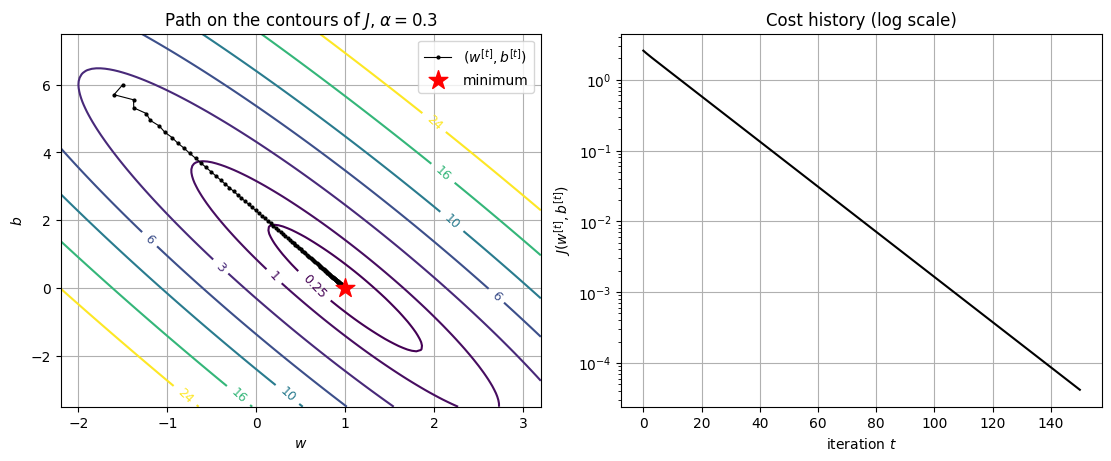

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
cs = ax[0].contour(W, B, J_grid, levels=levels, cmap='viridis')
ax[0].clabel(cs, fmt='%g', fontsize=9)
ax[0].plot(path[:, 0], path[:, 1], 'k.-', ms=4, lw=0.8, label='$(w^{[t]}, b^{[t]})$')
ax[0].scatter(1, 0, marker='*', c='r', s=200, zorder=3, label='minimum')
ax[0].set(xlabel='$w$', ylabel='$b$', title=r'Path on the contours of $J$, $\alpha = 0.3$')
ax[0].legend()
ax[1].semilogy(J_hist, 'k-')
ax[1].set(xlabel='iteration $t$', ylabel='$J(w^{[t]}, b^{[t]})$', title='Cost history (log scale)')
for a in ax:
    a.grid(True)
plt.show()

The path first runs quickly downhill into the long, narrow valley of the bowl and then moves slowly along the valley towards the minimum. The cost decreases at every iteration. Plotting the cost history is the standard way to check that gradient descent works: if $J$ ever **increases**, the learning rate is too large (or the gradient code has a bug).

### The learning rate

We now run the same example with several learning rates and compare the cost histories.

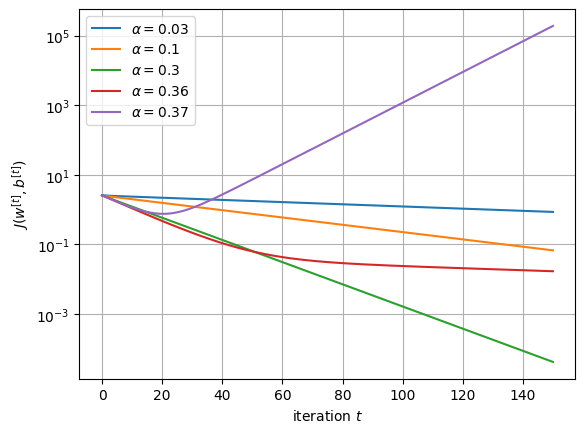

In [18]:
for alpha in [0.03, 0.1, 0.3, 0.36, 0.37]:
    _, _, J_hist_alpha, _ = gradient_descent(x_toy, y_toy, w=-1.5, b=6.0, alpha=alpha, n_iters=150)
    plt.semilogy(J_hist_alpha, label=rf'$\alpha = {alpha}$')
plt.xlabel('iteration $t$')
plt.ylabel('$J(w^{[t]}, b^{[t]})$')
plt.legend()
plt.grid(True)
plt.show()

- $\alpha = 0.03$ and $0.1$: the cost decreases, but slowly.
- $\alpha = 0.3$: the fastest convergence of the values tried.
- $\alpha = 0.36$: still converges, but slowly, because the iterates overshoot and oscillate across the valley.
- $\alpha = 0.37$: the cost decreases for about 20 iterations, but then grows without bound: gradient descent **diverges**. A diverging run can look fine at first, so always look at the whole cost history.

The best learning rate is neither the smallest nor the largest. There is a critical value, here about $0.36$, above which gradient descent diverges, just as $\alpha < 1$ was needed for $f(x) = (x-1)^2$ in the lecture.

::: {.callout-note collapse="true" title="For the curious: where does the critical value come from?"}
In the lecture, gradient descent on a quadratic with curvature $\kappa = f''$ converges if and only if $0 < \alpha < 2/\kappa$. The cost $J(w,b)$ is a quadratic function of two variables, and its curvature is described by the **Hessian**, the matrix of second derivatives. Differentiating the gradient formulas once more gives
$$
H = \begin{pmatrix} \dfrac{\partial^2 J}{\partial w^2} & \dfrac{\partial^2 J}{\partial w\,\partial b} \\[8pt]
\dfrac{\partial^2 J}{\partial b\,\partial w} & \dfrac{\partial^2 J}{\partial b^2} \end{pmatrix}
= \begin{pmatrix} \overline{x^2} & \bar x \\ \bar x & 1 \end{pmatrix}.
$$
Its eigenvalues $\lambda_{\min} \le \lambda_{\max}$ are the curvatures of the bowl along its flattest and its steepest direction (the axes of the contour ellipses). Gradient descent converges if and only if $0 < \alpha < 2/\lambda_{\max}$. The ratio $\lambda_{\max}/\lambda_{\min}$ measures how long and narrow the valley is; the larger it is, the slower the progress along the valley.

In [19]:
def hessian_eigenvalues(x):
    """Eigenvalues (in ascending order) of the Hessian of the squared-error cost."""
    H = np.array([[np.mean(x ** 2), np.mean(x)],
                  [np.mean(x),      1.0       ]])
    return np.linalg.eigvalsh(H)

for name, x_data in [("toy", x_toy), ("diabetes", x_train)]:
    lam_min, lam_max = hessian_eigenvalues(x_data)
    print(f"{name:8s}: 2/lambda_max = {2 / lam_max:.5f}, "
          f"lambda_max/lambda_min = {lam_max / lam_min:,.0f}")

toy     : 2/lambda_max = 0.36059, lambda_max/lambda_min = 46
diabetes: 2/lambda_max = 0.00279, lambda_max/lambda_min = 26,333


Note that $H$ depends only on the inputs $x^{(i)}$, not on the targets $y^{(i)}$.
:::

### Gradient descent on the diabetes data

The BMI values are large (between 18 and 42), so $\overline{x^2} \approx 717$ and the bowl is very steep in the $w$-direction. As a result, the learning rate must be below about $0.0028$. At the same time the bowl is an extremely long and narrow valley, along which progress is slow. Let us run gradient descent with $\alpha = 0.0025$ from $(w, b) = (0, 0)$.

In [20]:
w_gd, b_gd, J_hist, path = gradient_descent(x_train, y_train, w=0.0, b=0.0,
                                            alpha=0.0025, n_iters=100_000)
for t in [0, 10, 100, 1_000, 10_000, 100_000]:
    print(f"t = {t:7,d}: w = {path[t, 0]:7.3f}, b = {path[t, 1]:8.3f}, J = {J_hist[t]:9.2f}")
print(f"closed form: w = {w_star:7.3f}, b = {b_star:8.3f}, J = {J_min:9.2f}")

t =       0: w =   0.000, b =    0.000, J =  14537.24
t =      10: w =   5.325, b =    0.116, J =   2246.64
t =     100: w =   5.911, b =   -0.583, J =   2132.23
t =   1,000: w =   6.167, b =   -7.539, J =   2110.69
t =  10,000: w =   8.028, b =  -57.992, J =   1993.89
t = 100,000: w =  10.228, b = -117.642, J =   1945.23
closed form: w =  10.233, b = -117.773, J =   1945.23


The cost drops quickly in the first iterations, but about $100\,000$ iterations are needed to get close to the closed-form solution, for a problem with only two parameters! The cause is the **scale of the input** $x$, not the size of the targets $y$. In part 2b of the lecture (Lab 4) we fix this with **feature scaling**.

### Challenges

1. Run gradient descent on the diabetes data with $\alpha = 0.0029$, just above the critical value, for $50$ iterations. What happens to the cost?
2. Run it with a very small learning rate, $\alpha = 10^{-5}$, for $10\,000$ iterations. How far from $(w^*, b^*)$ do you get?
3. Suppose we force $w = 0$, so the model predicts the constant $b$ for every patient. Which $b$ minimises $J$? Derive it from $\partial J/\partial b = 0$ and check your answer with `compute_cost` and `np.mean(y_train)`.

## Summary

- The cost $J(w,b) = \frac{1}{2m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)^2$ is a convex quadratic bowl; vectorised, it is two lines of NumPy.
- For univariate linear regression the minimum has a closed form, which agrees with scikit-learn.
- Check gradient code against finite differences before using it.
- Gradient descent updates $w$ and $b$ simultaneously; plot the cost history to check that $J$ decreases.
- If $\alpha$ is too small, convergence is slow; above a critical value, gradient descent diverges. The critical value and the speed of convergence depend on the scale of the input $x$, which motivates feature scaling in part 2b (Lab 4).